Importing Data

In [ ]:
!pip install wfdb==3.4.0
!wget -q https://www.physionet.org/static/published-projects/mitdb/mit-bih-arrhythmia-database-1.0.0.zip
!unzip -qo /content/mit-bih-arrhythmia-database-1.0.0.zip

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 KB 3.5 MB/s eta 0:00:00


Getting data into usable Arrays

360


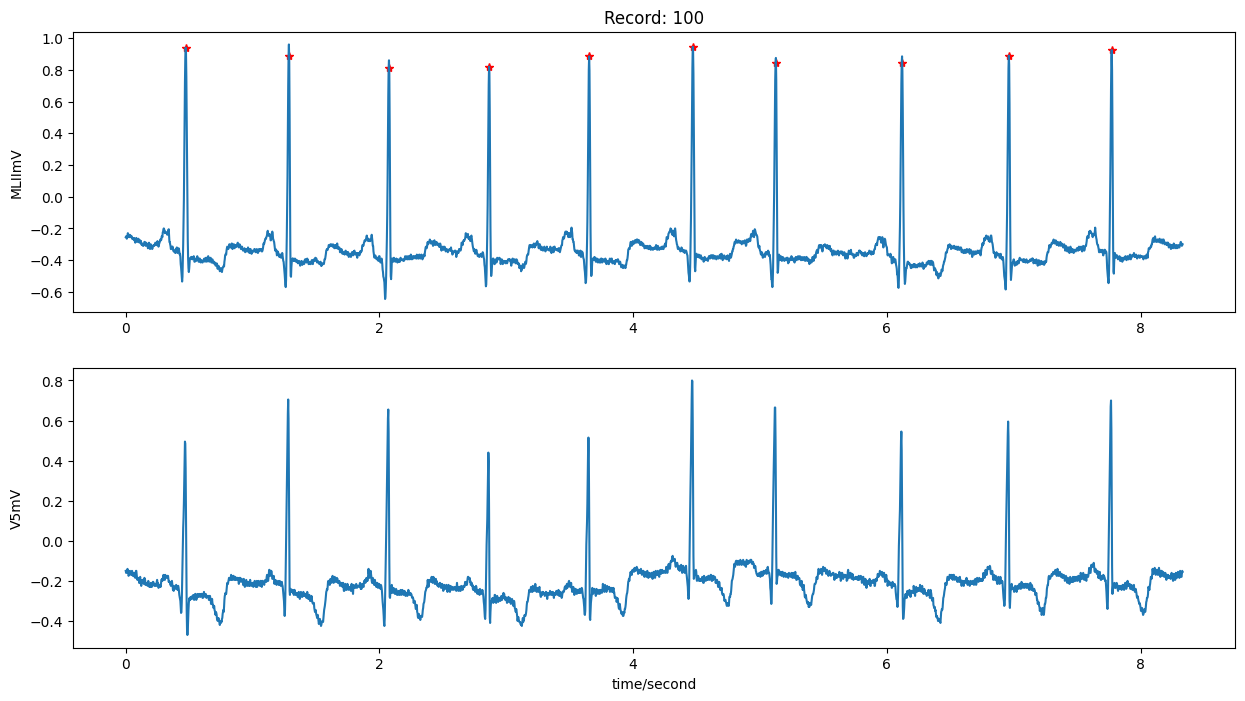

In [ ]:
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.misc import derivative

data = 100
length = 3200
order = 1
t = np.linspace(0, 1, length, endpoint=False)

filename = f'/content/mit-bih-arrhythmia-database-1.0.0/{str(data)}'
record = wfdb.rdrecord(filename, sampfrom=200, sampto=length,)
ecg = pd.DataFrame(np.array([list(range(len(record.adc()))),record.adc()[:,0]]).T,columns=['TimeStamp','ecg'])
input = ecg.iloc[:,1]

annotation = wfdb.rdann(filename, 'atr', sampfrom=200, sampto=length,shift_samps=True)
Fs = annotation.fs
print(Fs)

wfdb.plot_wfdb(record=record, annotation=annotation, time_units='seconds',figsize=(15,8))


ECG Signal Simulation

In [ ]:
import logging
import threading
import time

# The goal is to have a thread running alongside the main program which will
# output the necessary ecg data (which may affect timing results).
class ECG_Simulator():

  def __init__(self, ecg, sample_freq):
    self.ecg = ecg
    self.current_ecg = 0.0
    self.new_val = False
    self.sample_freq = sample_freq

  def simulate(self):
    for ecg_reading in self.ecg:
      self.current_ecg = ecg_reading
      self.new_val = True
      # print(self.current_ecg)
      # logging.info(self.current_ecg)
      time.sleep(1/self.sample_freq) # Based on the sampling rate

  # To be used along with the main algorithm, which generally should get, store
  # and operate on the ECG data.
  def checkECG(self):
    check = self.new_val
    self.new_val = False
    return check

  def getECG(self):
    return self.current_ecg

# Testing Purposes

# print("Starting")
# simulator = ECG_Simulator(input)
# sim = threading.Thread(target = simulator.simulate)
# sim.start()

# while True:
#   print(simulator.getECG())
#   time.sleep(1)

# sim.join()

Pan-Tompkins Filters & Algorithm

In [ ]:
class ECG_Solver():

  def __init__(self):

    # ----- PREPROCESSING VARIABLES ----- #

    # Buffers
    self.ecg_raw = np.zeros(13)
    self.ecg_lp = np.zeros(33)
    self.ecg_hp = np.zeros(5)
    self.ecg_der = 0

    self.win_size = round(0.150 * annotation.fs) # need to double check this (not sure how this is derived)
    self.ecg_sqr = np.zeros(self.win_size)

    self.ecg_win = 0;

    self.raw_index = -1
    self.lp_index = -1
    self.hp_index = -1
    self.hp_dindex = -1 # Used to account for x(nT+2T)
    self.sqr_index = -1

    self.lpout_1 = 0 # low pass y(nT-T)
    self.lpout_2 = 0 # low pass y(nT-2T)
    self.hpout_1 = 0 # high pass y(nT-T)

    # ----- HEART RATE ALG. VARIABLES ----- #

    # ----- PREPROCESSING METHODS ----- #

  def readECG(self, inputData):

    # array shuffling for each new value added (maybe this could be faster if
    # implemented in hardware?)
    if (self.raw_index != 12):
      self.raw_index += 1
    else:
      self.ecg_raw = np.roll(self.ecg_raw, -1)

    self.ecg_raw[self.raw_index] = inputData

    return self.ecg_raw

  # Below they should be considered as private functions, but this may be tentative

  def lpFilter(self):

    # array shuffling for each new value added (maybe this could be faster if
    # implemented in hardware?)


    if (self.lp_index != 32):
      self.lp_index += 1
    else:
      self.ecg_lp = np.roll(self.ecg_lp, -1)

    # y(nT) = 2y(nT - T) - y(nT - 2T) + x(nT) - 2x(nT - 6T) + x(nT - 12T)
    self.ecg_lp[self.lp_index] = 2 * self.lpout_1 - self.lpout_2 + self.ecg_raw[self.raw_index]

    if (self.raw_index >= 6):
      self.ecg_lp[self.lp_index] -= 2 * self.ecg_raw[self.raw_index - 6]

    if (self.raw_index >= 12):
      self.ecg_lp[self.lp_index] += self.ecg_raw[self.raw_index - 12]

    self.lpout_2 = self.lpout_1
    self.lpout_1 = self.ecg_lp[self.lp_index]

    return self.ecg_lp

  def hpFilter(self):

    # array shuffling for each new value added (maybe this could be faster if
    # implemented in hardware?)
    if (self.hp_index != 4):
      self.hp_index += 1
      if (self.hp_dindex != 2):
        self.hp_dindex += 1
    else:
      self.ecg_hp = np.roll(self.ecg_hp, -1)

    # y(nT) = 32x(nT - 16T) - y(nT - T) - x(nT) + x(nT - 32T)
    self.ecg_hp[self.hp_index] = -1 * (self.hpout_1 + self.ecg_lp[self.lp_index])

    if (self.lp_index >= 16):
      self.ecg_hp[self.hp_index] += 32 * self.ecg_lp[self.lp_index - 16]

    if (self.lp_index >= 32):
      self.ecg_hp[self.hp_index] += self.ecg_lp[self.lp_index - 32]

    self.hpout_1 = self.ecg_hp[self.hp_index]

    return self.ecg_hp

  def derFilter(self):

    # y(nT) = [-x(nT - 2T) - 2x(nT - T) + 2x(nT + T) + x(nT + 2T)]/(8T)
    self.ecg_der = 0

    if (self.hp_index >= 1):
      self.ecg_der -= self.ecg_hp[self.hp_dindex - 1]

    if (self.hp_index >= 2):
      self.ecg_der -= self.ecg_hp[self.hp_dindex - 2]

    if (self.hp_index >= 3):
      self.ecg_der += self.ecg_hp[self.hp_dindex + 1]

    if (self.hp_index >= 4):
      self.ecg_der += self.ecg_hp[self.hp_dindex + 2]

    # Double check this, may be as below (annotation.fs is sampling frequency)
    # self.ecg_der = (self.ecg_der * annotation.fs) /8
    self.ecg_der /= 8

    return self.ecg_der

  def squaring(self):

    if (self.sqr_index != self.win_size - 1):
      self.sqr_index +=1
    else:
      self.ecg_sqr = np.roll(self.ecg_sqr, -1)

    # y(nT) = [x(nT)]^2
    self.ecg_sqr[self.sqr_index] = np.square(self.ecg_der)

    return self.ecg_sqr

  def winIntegrator(self):
    # y(nT) = [y(nT - (N-1)T) + x(nT - (N-2)T) + ... + x(nT)]/N
    self.ecg_win = 0;

    for i in range(self.win_size):
        self.ecg_win += self.ecg_sqr[i]

    return self.ecg_win;

  # ----- HEART RATE ALG. METHODS ----- #



Testing & Graphs

Starting


Text(0.5, 1.0, 'Integrated Signal')

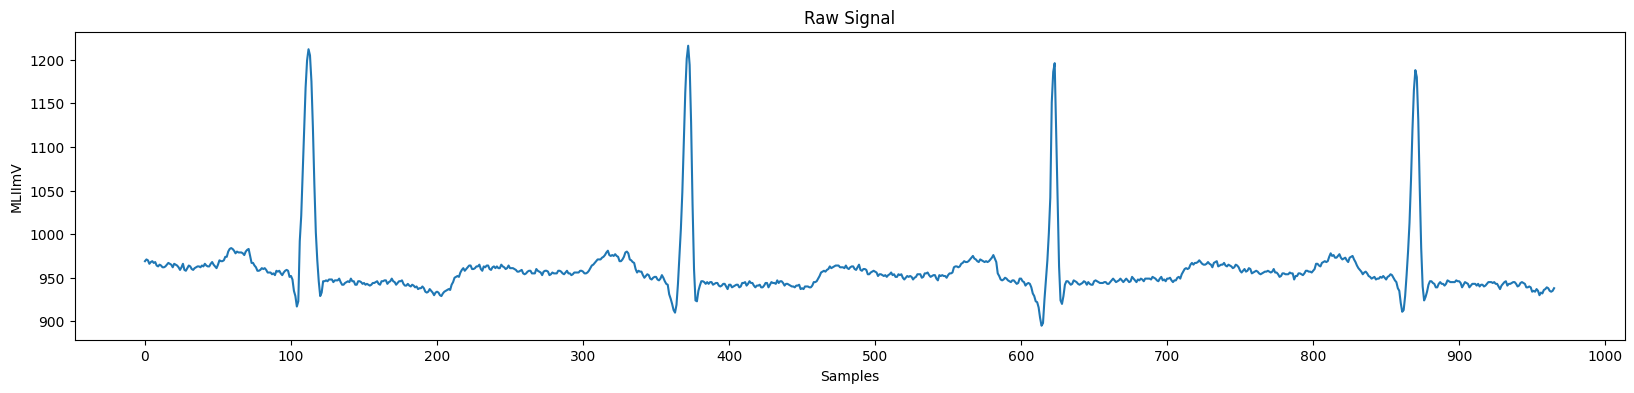

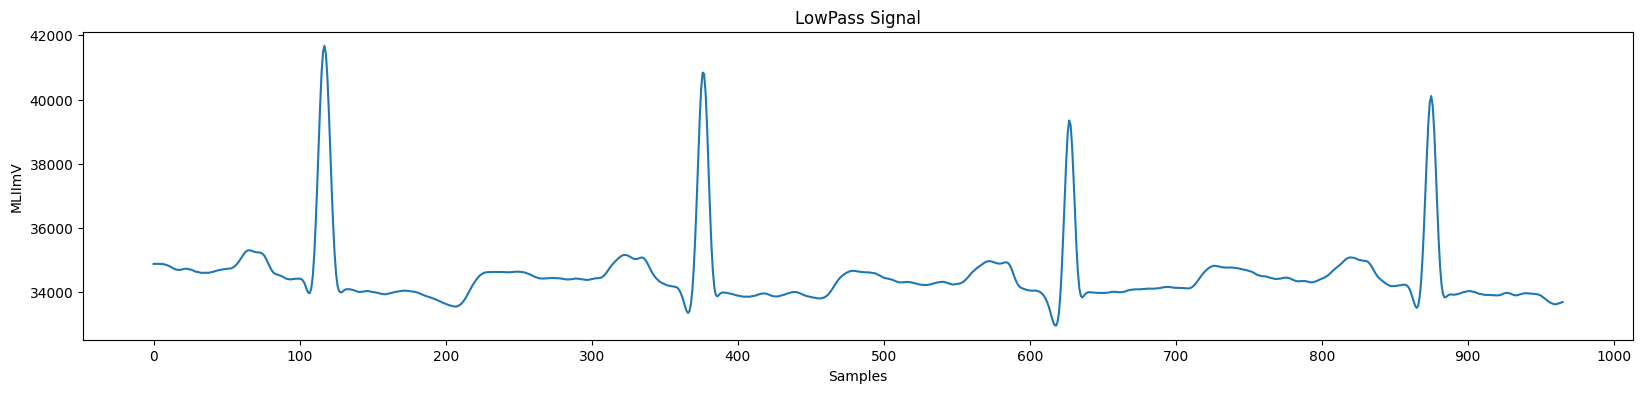

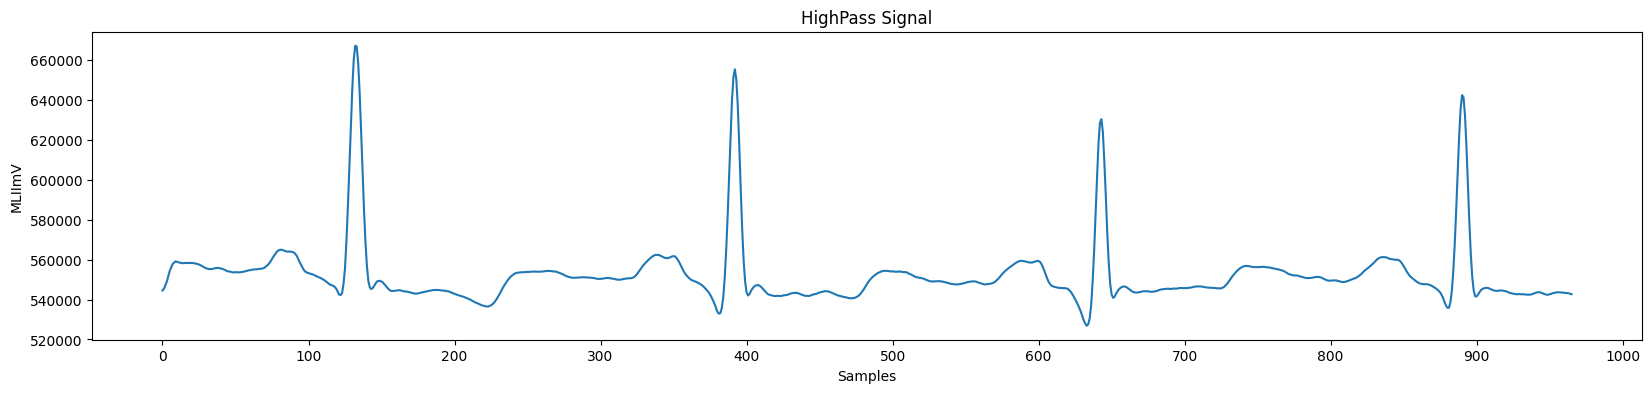

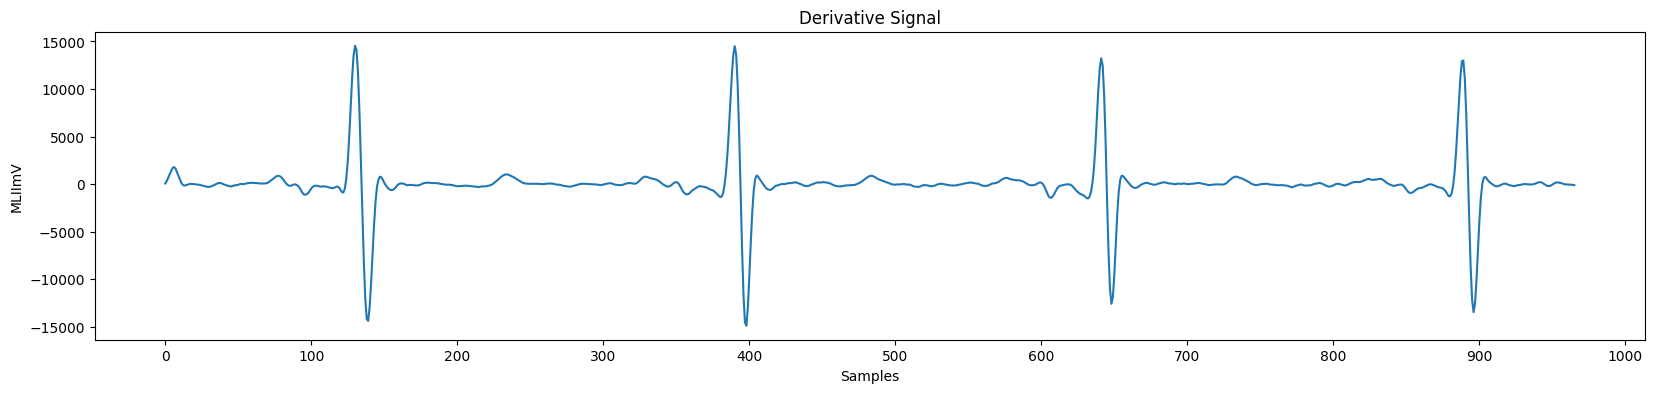

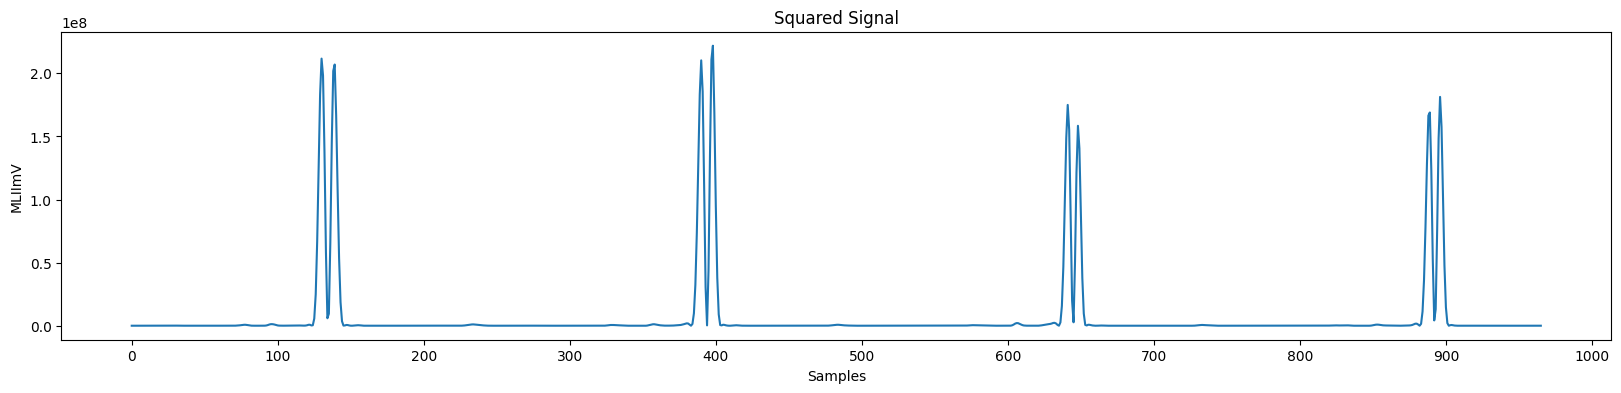

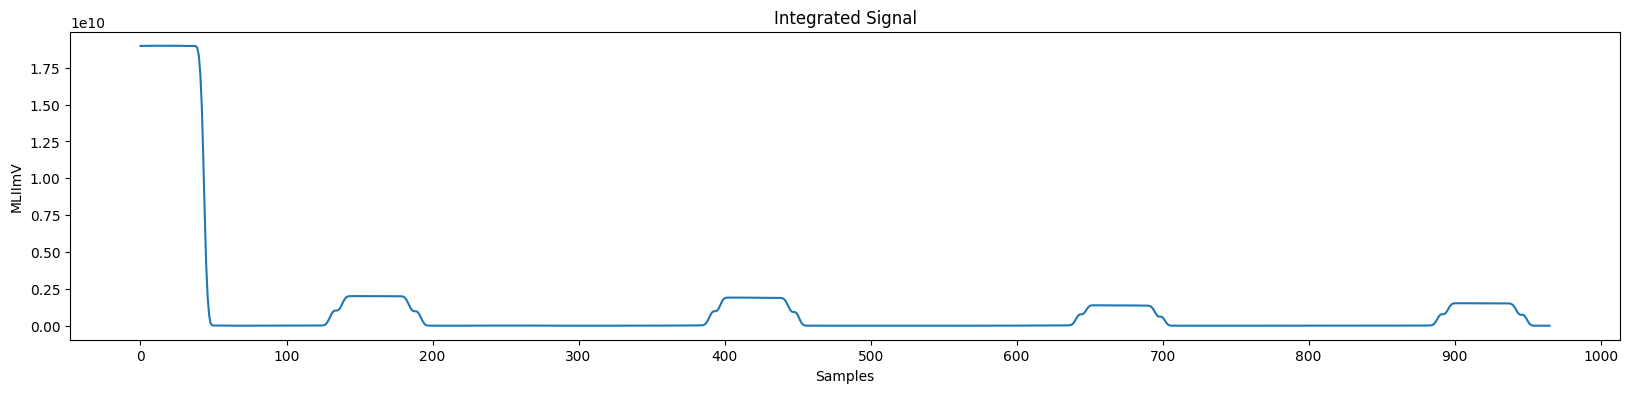

In [ ]:
print("Starting")
simulator = ECG_Simulator(input, Fs)
solver = ECG_Solver()
sim = threading.Thread(target = simulator.simulate)
sim.start()

test_data_r = []
test_data_l = []
test_data_h = []
test_data_d = []
test_data_s = []
test_data_w = []

while len(test_data_r) < 1000:
  if (simulator.checkECG()):
    test_data_r.append(solver.readECG(simulator.getECG())[12])
    test_data_l.append(solver.lpFilter()[32])
    test_data_h.append(solver.hpFilter()[4])
    test_data_d.append(solver.derFilter())
    test_data_s.append(solver.squaring()[round(0.150 * annotation.fs)-1])
    test_data_w.append(solver.winIntegrator())

    # print("\n---\n")

sim.join()

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_r)+1, 100))
plt.plot(test_data_r[32:len(test_data_r)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("Raw Signal")

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_l)+1, 100))
plt.plot(test_data_l[32:len(test_data_l)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("LowPass Signal")

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_h)+1, 100))
plt.plot(test_data_h[32:len(test_data_h)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("HighPass Signal")

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_d)+1, 100))
plt.plot(test_data_d[32:len(test_data_d)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("Derivative Signal")

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_s)+1, 100))
plt.plot(test_data_s[32:len(test_data_s)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("Squared Signal")

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_w)+1, 100))
plt.plot(test_data_w[32:len(test_data_w)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("Integrated Signal")

In [ ]:
testarr = test_data_r.copy()
testarr1 = test_data_r.copy()

x = np.zeros(33)
y = np.zeros(33)

outarr = []
for i in range(len(testarr)):
  # y(nT) = 32x(nT - 16T) - y(nT - T) - x(nT) + x(nT - 32T)
  x[0] = testarr[i];

  y[0] = 32*x[16] - y[1] - x[0] - 2*x[6] + x[32]
  data = y[0]/8
  print(data)

  x[32] = x[31]; x[31] = x[30]; x[30] = x[29]; x[29] = x[28];
  x[28] = x[27]; x[27] = x[26]; x[26] = x[25]; x[25] = x[24];
  x[24] = x[23]; x[23] = x[22]; x[22] = x[21]; x[21] = x[20];
  x[20] = x[19]; x[19] = x[18]; x[18] = x[17]; x[17] = x[16];
  x[16] = x[15]; x[15] = x[14]; x[14] = x[13]; x[13] = x[12];
  x[12] = x[11]; x[11] = x[10]; x[10] = x[9]; x[9] = x[8];
  x[8] = x[7]; x[7] = x[6]; x[6] = x[5]; x[5] = x[4];
  x[4] = x[3]; x[3] = x[2]; x[2] = x[1]; x[1] = x[0];

  y[32] = y[31]; y[31] = y[30]; y[30] = y[29]; y[29] = y[28];
  y[28] = y[27]; y[27] = y[26]; y[26] = y[25]; y[25] = y[24];
  y[24] = y[23]; y[23] = y[22]; y[22] = y[21]; y[21] = y[20];
  y[20] = y[19]; y[19] = y[18]; y[18] = y[17]; y[17] = y[16];
  y[16] = y[15]; y[15] = y[14]; y[14] = y[13]; y[13] = y[12];
  y[12] = y[11]; y[11] = y[10]; y[10] = y[9]; y[9] = y[8];
  y[8] = y[7]; y[7] = y[6]; y[6] = y[5]; y[5] = y[4];
  y[4] = y[3]; y[3] = y[2]; y[2] = y[1]; y[1] = y[0];

  outarr.append(data)



0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
-121.75
0.125
-122.0
0.375
-122.125
0.75
-365.75
1.0
-366.125
1.625
-366.5
2.625
-366.625
2.875
-366.75
3.0
3528.75
0.0
3537.0
-7.375
3540.0
-19.625
3543.25
-18.5
3539.625
-22.125
3542.75
-29.875
3538.125
-37.125
3551.0
-33.125
3680.125
-48.5
3680.125
-51.875
3688.25
-53.0
3696.75
-56.375
3684.5
-60.625
3696.25
-69.25
3700.875
-85.875
3696.75
-77.0
3693.75
-85.625
3694.5
-82.875
3702.5
-73.625
3699.625
-78.75
3702.625
-82.75
3699.625
-86.75
3683.625
-67.875
3691.25
-83.75
3675.375
-72.875
3683.375
-76.625
3675.875
-83.875
3679.5
-77.0
3682.5
-72.25
3678.75
-64.375
3673.75
-60.125
3672.0
-64.5
3670.875
-53.25
3679.25
-64.5
3669.25
-72.875
3676.625
-64.75
3697.25
-67.5
3700.25
-51.375
3701.125
-54.0
3725.625
-50.0
3737.125
-45.875
3735.375
-64.375
3742.875
-67.75
3743.5
-70.25
3736.5
-66.5
3748.0
-53.75
3716.125
-86.0
3717.75
-97.75
3709.625
-113.0
3710.5
-111.25
3718.75
-115.75
3722.375
-122.125
3711.0
-126.875
3715.375
-125.625
3703.125
-

Text(0.5, 1.0, 'highpass')

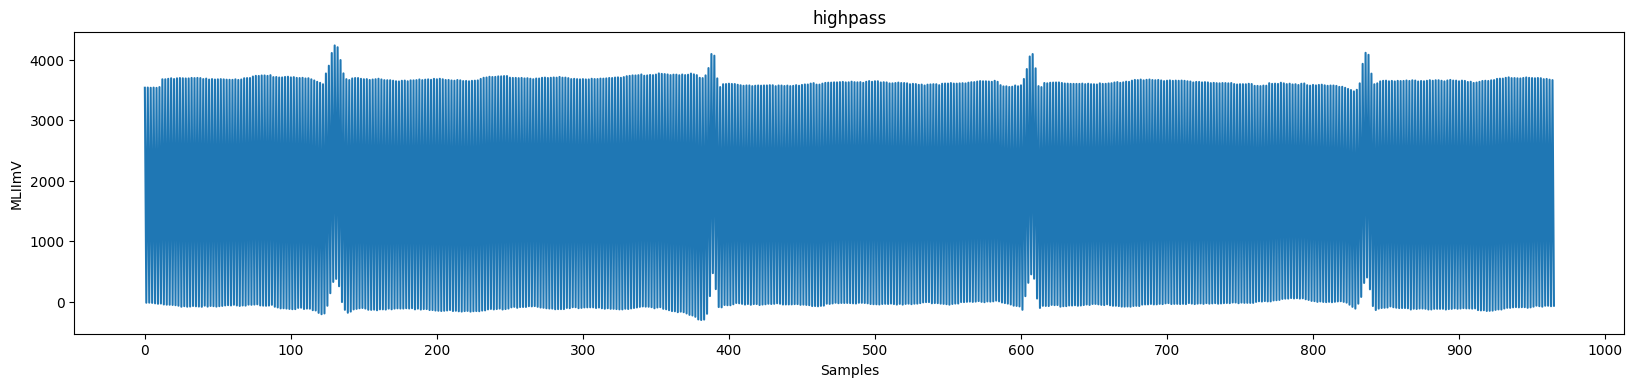

In [ ]:
plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(outarr)+1, 100))
plt.plot(outarr[32:len(outarr)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("highpass")

In [ ]:
print(outarr)

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 974.0, 973.0, 975.0, 973.0, 974.0, 971.0, 2920.0, 2918.0, 2921.0, 2916.0, 2919.0, 2911.0, 3886.0, 3883.0, 3886.0, 3883.0, 3888.0, 3877.0, 3876.0, 3871.0, 3878.0, 3879.0, 3886.0, 3875.0, 3871.0, 3866.0, 3876.0, 3875.0, 3882.0, 3872.0, 3865.0, 3864.0, 3871.0, 3865.0, 3869.0, 3861.0, 3858.0, 3863.0, 3863.0, 3856.0, 3858.0, 3855.0, 3857.0, 3862.0, 3855.0, 3856.0, 3860.0, 3855.0, 3851.0, 3854.0, 3847.0, 3855.0, 3858.0, 3847.0, 3839.0, 3846.0, 3847.0, 3851.0, 3848.0, 3842.0, 3839.0, 3847.0, 3851.0, 3851.0, 3847.0, 3852.0, 3853.0, 3854.0, 3853.0, 3850.0, 3851.0, 3861.0, 3869.0, 3863.0, 3860.0, 3859.0, 3863.0, 3869.0, 3887.0, 3883.0, 3886.0, 3893.0, 3894.0, 3889.0, 3908.0, 3908.0, 3915.0, 3920.0, 3916.0, 3906.0, 3919.0, 3921.0, 3916.0, 3907.0, 3902.0, 3896.0, 3902.0, 3903.0, 3887.0, 3871.0, 3871.0, 3865.0, 3865.0, 3858.0, 3847.0, 3840.0, 3845.0, 3840.0, 3837.0, 3834.0, 3827.0, 3827.0, 3833.0, 3827.0, 3820.0, 3831.0, 3828.0, 3830.0, 3

Text(0.5, 1.0, 'lowpass')

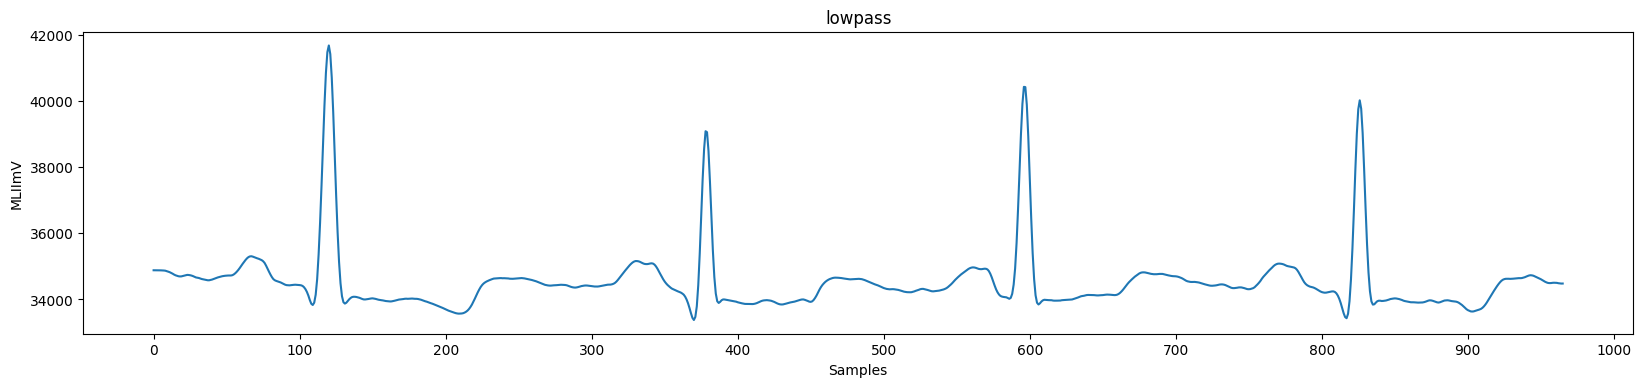

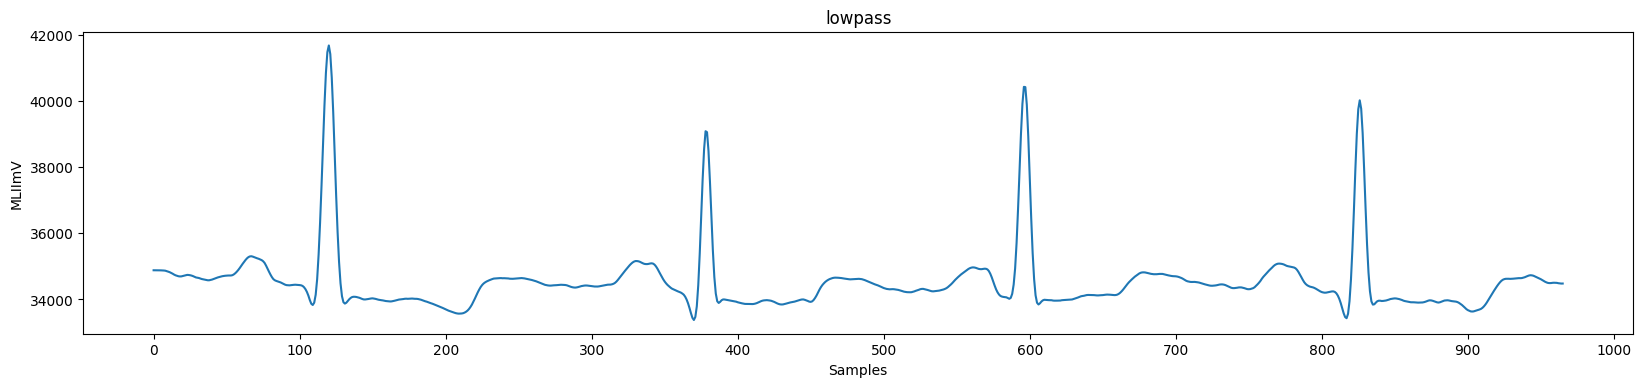

In [ ]:
# Initialize result
sig = np.zeros(1000)

testarr = test_data_r.copy()

for index in range(len(testarr)):
  sig[index] = testarr[index]

  if (index >= 1):
    sig[index] += 2*sig[index-1]

  if (index >= 2):
    sig[index] -= sig[index-2]

  if (index >= 6):
    sig[index] -= 2*testarr[index-6]

  if (index >= 12):
    sig[index] += testarr[index-12]

# Copy the result of the low pass filter
result = sig.copy()

# Apply the derivative filter using the equation given
for index in range(len(testarr)):
  result[index] = -1*sig[index]

  if (index >= 1):
    result[index] -= result[index-1]

  if (index >= 16):
    result[index] += 32*sig[index-16]

  if (index >= 32):
    result[index] += sig[index-32]

plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(test_data_l)+1, 100))
plt.plot(test_data_l[32:len(test_data_l)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("lowpass")


plt.figure(figsize = (20,4), dpi = 100)
plt.xticks(np.arange(0, len(sig)+1, 100))
plt.plot(sig[32:len(sig)-2])
plt.xlabel('Samples')
plt.ylabel('MLIImV')
plt.title("lowpass")